# Part A: Regression on California test scores



### 1. Find the url for the California Test Score Data Set from the following website: https://vincentarelbundock.github.io/Rdatasets/datasets.html Read through the "DOC" file to understand the variables in the dataset, then use the following url to import the data: https://vincentarelbundock.github.io/Rdatasets/csv/Ecdat/Caschool.csv  The target data (i.e. the dependent variable) is named "testscr". You can use all variables in the data except for "readscr" and "mathscr" in the following analysis (those two variables were used to generate the dependent variable).

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib as mpl
import seaborn as sns

In [2]:
df = pd.read_csv('https://vincentarelbundock.github.io/Rdatasets/csv/Ecdat/Caschool.csv')

In [3]:
display(df.head())

,rownames,distcod,county,district,grspan,enrltot,teachers,calwpct,mealpct,computer,testscr,compstu,expnstu,str,avginc,elpct,readscr,mathscr
0,1,75119,Alameda,Sunol Glen Unified,KK-08,195,10.900000,0.510200,2.040800,67,690.799988,0.343590,6384.911133,17.889910,22.690001,0.000000,691.599976,690.000000
1,2,61499,Butte,Manzanita Elementary,KK-08,240,11.150000,15.416700,47.916698,101,661.200012,0.420833,5099.380859,21.524664,9.824000,4.583333,660.500000,661.900024
2,3,61549,Butte,Thermalito Union Elementary,KK-08,1550,82.900002,55.032299,76.322601,169,643.599976,0.109032,5501.954590,18.697226,8.978000,30.000002,636.299988,650.900024
3,4,61457,Butte,Golden Feather Union Elementary,KK-08,243,14.000000,36.475399,77.049202,85,647.700012,0.349794,7101.831055,17.357143,8.978000,0.000000,651.900024,643.500000
4,5,61523,Butte,Palermo Union Elementary,KK-08,1335,71.500000,33.108601,78.427002,171,640.849976,0.128090,5235.987793,18.671329,9.080333,13.857677,641.799988,639.900024


### Pick 3 continuous variables from the data that you think are likely to have a relationship with the target feature. Visualize the univariate distribution of the target feature and each of these three explanatory variables.   

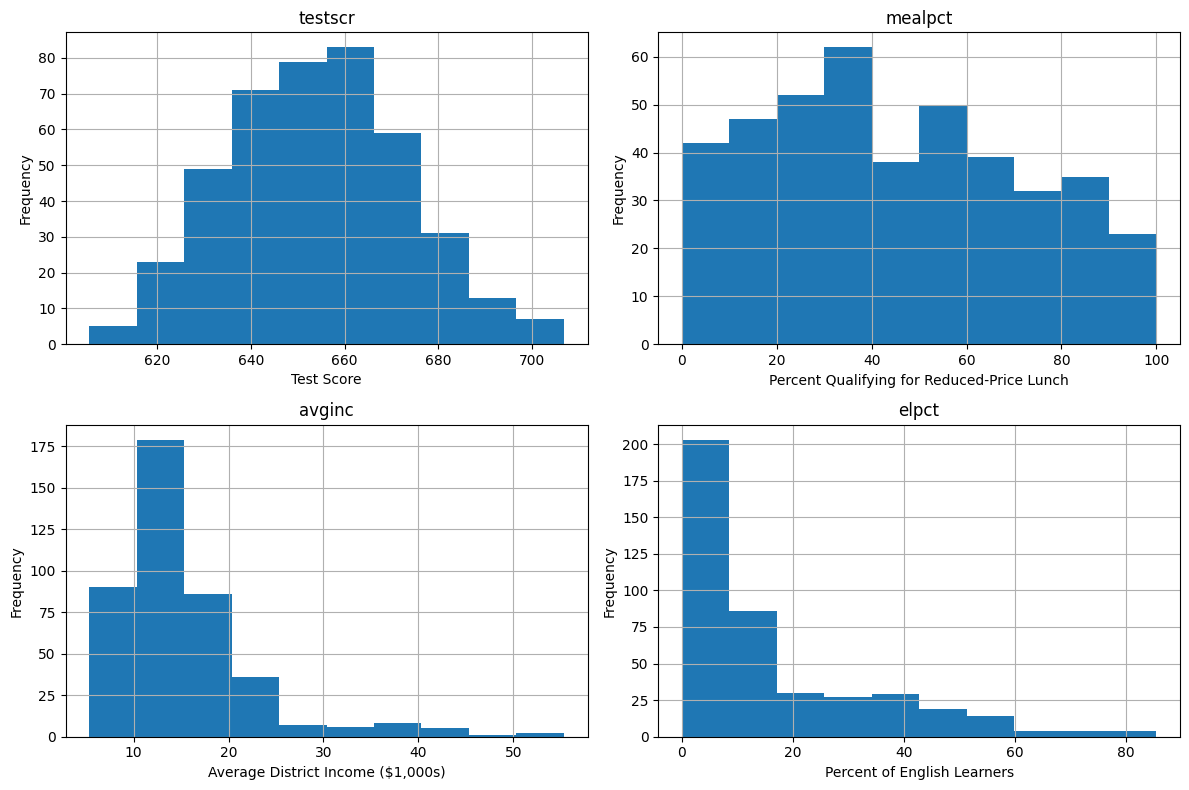

In [4]:
import matplotlib.pyplot as plt

target = 'testscr'
cont_variables = ["mealpct", "avginc", "elpct"]
relationship = [target] + cont_variables

axes = df[relationship].hist(figsize=(12, 8))

labels = {
    'testscr': 'Test Score',
    'mealpct': 'Percent Qualifying for Reduced-Price Lunch',
    'avginc': 'Average District Income ($1,000s)',
    'elpct': 'Percent of English Learners'
}

for ax in axes.flatten():
    title = ax.get_title()
    if title in labels:
        ax.set_xlabel(labels[title])
    else:
        ax.set_xlabel(title)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 4. Visualize the dependency of the target on each feature you just plotted.


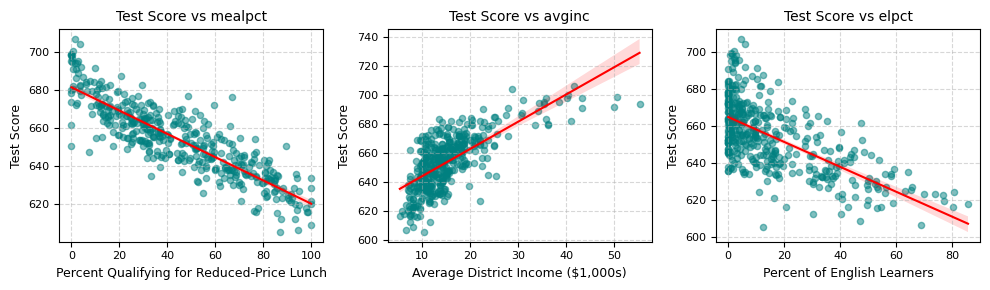

In [5]:
target = 'testscr'
relationship = ["mealpct", "avginc", "elpct"]

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

labels = {
    'testscr': 'Test Score',
    'mealpct': 'Percent Qualifying for Reduced-Price Lunch',
    'avginc': 'Average District Income ($1,000s)',
    'elpct': 'Percent of English Learners'
}

for i, col in enumerate(cont_variables):
    sns.regplot(data=df, x=col, y=target, ax=axes[i],
                scatter_kws={'alpha':0.5, 'color': 'teal', 's': 20},
                line_kws={'color': 'red', 'linewidth': 1.5})

    axes[i].set_title(f'{labels[target]} vs {col}', fontsize=10)
    axes[i].set_xlabel(labels.get(col, col), fontsize=9)
    axes[i].set_ylabel(labels[target], fontsize=9)
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].tick_params(labelsize=8)

plt.tight_layout()
plt.show()

### 4. Build a KNN Regression model that evaluates the relationship between the target variable and all of the quantitative features (enrltot, teachers, calwpct, mealpct, computer, compstu, expnstu, str, avginc, & elpct). Make sure that you first split the data into training and test sets and tune the hyperparameters where possible using GridSearchCV. Run one version with StandardScaler and one version without it.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
import numpy as np

target = 'testscr'
features = ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y)

print(X_test.shape)
print(X_train.shape)

(105, 10)
(315, 10)


In [7]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)
print(np.round(knn.score(X_test, y_test), 2))

-0.04


In [8]:
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train, y_train)

print(f'accuracy: {np.round(knn.score(X_test, y_test), 2)}')

accuracy: -0.02


In [9]:
param_grid = {'n_neighbors': np.arange(1, 15, 2)}
grid = GridSearchCV(KNeighborsRegressor(), param_grid=param_grid, cv=10, scoring='r2')
grid.fit(X_train, y_train)
print("Best cross-validation score (from training set): {:.3f}".format(grid.best_score_))
print("Best parameters: {}".format(grid.best_params_))

print("Test set score: {:.3f}".format(grid.score(X_test, y_test)))

Best cross-validation score (from training set): -0.001
Best parameters: {'n_neighbors': np.int64(13)}
Test set score: 0.001


In [10]:
# regression without standardscaler
from sklearn import preprocessing
X_train = np.array([[ 1., -1.,  2.],
                    [ 2.,  0.,  0.],
                    [ 0.,  1., -1.]])

print(X_train)
print(X_train.mean(axis=0))
print(X_train.std(axis=0))

[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]
[1.         0.         0.33333333]
[0.81649658 0.81649658 1.24721913]


In [11]:
X_scaled = preprocessing.scale(X_train)

print(X_scaled)
print(X_scaled.mean(axis=0))
print(X_scaled.std(axis=0))

[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]
[0. 0. 0.]
[1. 1. 1.]


In [12]:
# regression with standardscaler
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

features = ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']
X = df[features]
y = df['testscr']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaler mean values for the 10 features:")
print(scaler.mean_)

Scaler mean values for the 10 features:
[2.74421270e+03 1.34023327e+02 1.29420964e+01 4.40788704e+01
 3.13171429e+02 1.35983404e-01 5.31344616e+03 1.97189091e+01
 1.54183806e+01 1.54357710e+01]


In [13]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn import preprocessing

features = ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']
X = df[features]
y = df['testscr']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

ridge = Ridge().fit(X_train_scaled, y_train)

X_test_scaled = scaler.transform(X_test)
print(f'Test Score: {ridge.score(X_test_scaled, y_test)}')


Test Score: 0.8069708569856147


### 5. Repeat Question 4 three more times, each time using one of the linear models that we have learned for regression: Linear Regression (without regularization), Ridge Regression, & Lasso Regression.

**Linear Regression**

In [14]:
df = df.loc[:, df.columns != 'rownames']

y = df['testscr']
X = df.loc[:, df.columns != 'testscr']

print(y[0:5])
display(X.head())

0    690.799988
1    661.200012
2    643.599976
3    647.700012
4    640.849976
Name: testscr, dtype: float64


,distcod,county,district,grspan,enrltot,teachers,calwpct,mealpct,computer,compstu,expnstu,str,avginc,elpct,readscr,mathscr
0,75119,Alameda,Sunol Glen Unified,KK-08,195,10.900000,0.510200,2.040800,67,0.343590,6384.911133,17.889910,22.690001,0.000000,691.599976,690.000000
1,61499,Butte,Manzanita Elementary,KK-08,240,11.150000,15.416700,47.916698,101,0.420833,5099.380859,21.524664,9.824000,4.583333,660.500000,661.900024
2,61549,Butte,Thermalito Union Elementary,KK-08,1550,82.900002,55.032299,76.322601,169,0.109032,5501.954590,18.697226,8.978000,30.000002,636.299988,650.900024
3,61457,Butte,Golden Feather Union Elementary,KK-08,243,14.000000,36.475399,77.049202,85,0.349794,7101.831055,17.357143,8.978000,0.000000,651.900024,643.500000
4,61523,Butte,Palermo Union Elementary,KK-08,1335,71.500000,33.108601,78.427002,171,0.128090,5235.987793,18.671329,9.080333,13.857677,641.799988,639.900024


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

features = ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']
X = df[features]
y = df['testscr']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
print(f'Train Score: {lr.score(X_train, y_train):.4f}')
print(f'Test Score: {lr.score(X_test, y_test):.4f}')
print(f"columns: {list(X_train.columns)}")
print("\nlr.coef_: "+str(lr.coef_))
print("\nlr.intercept_: {}".format(lr.intercept_))

Train Score: 0.8055
Test Score: 0.8070
columns: ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']

lr.coef_: [ 2.37299343e-04 -9.68465212e-03 -1.05122232e-01 -3.63632211e-01
  2.23981150e-03 -1.50110373e+00  1.87297506e-03 -3.68530746e-01
  5.17180694e-01 -1.97462843e-01]

lr.intercept_: 664.1994881014358


In [16]:
from sklearn.model_selection import cross_val_score

print("Training set score (no cross-validation): {:.2f}".format(
    lr.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(LinearRegression(), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    lr.score(X_test, y_test)))

Training set score (no cross-validation): 0.81
Training set score (with cross-validation): 0.78
Test set score: 0.81


**Ridge Regression**

In [17]:
from sklearn.linear_model import Ridge

ridge = Ridge().fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    ridge.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Ridge(), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    ridge.score(X_test, y_test)))

Training set score (no cross-validation): 0.81
Training set score (with cross-validation): 0.78
Test set score: 0.81


In [18]:
ridge10 = Ridge(alpha=10).fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    ridge10.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Ridge(alpha=10), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    ridge10.score(X_test, y_test)))

Training set score (no cross-validation): 0.81
Training set score (with cross-validation): 0.78
Test set score: 0.81


In [19]:
ridge01 = Ridge(alpha=0.1).fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    ridge01.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Ridge(alpha=0.1), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    ridge01.score(X_test, y_test)))

Training set score (no cross-validation): 0.81
Training set score (with cross-validation): 0.78
Test set score: 0.81


**Lasso Regression**

In [20]:
from sklearn.linear_model import Lasso

lasso = Lasso().fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    lasso.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Lasso(), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    lasso.score(X_test, y_test)))

print("\nNumber of features used: {}".format(np.sum(lasso.coef_ != 0)))
print("lasso.coef_: {}".format(lasso.coef_))

Training set score (no cross-validation): 0.80


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.132e+01, tolerance: 1.014e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.598e+02, tolerance: 8.856e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.722e+00, tolerance: 9.153e

Training set score (with cross-validation): 0.78
Test set score: 0.81

Number of features used: 8
lasso.coef_: [-3.49584411e-04  2.48458337e-03 -8.87553845e-02 -3.79258646e-01
  1.92100909e-03  0.00000000e+00  2.48224777e-03 -0.00000000e+00
  4.81690728e-01 -1.86583901e-01]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.008e+03, tolerance: 9.072e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.626e+03, tolerance: 9.039e+00
  model = cd_fast.enet_coordinate_descent(


In [21]:
lasso001 = Lasso(alpha=0.01).fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    lasso001.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Lasso(alpha=0.01), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    lasso001.score(X_test, y_test)))

print("\nNumber of features used: {}".format(np.sum(lasso001.coef_ != 0)))
print("\nlasso.coef_: {}".format(lasso001.coef_))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.518e+03, tolerance: 1.014e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.772e+03, tolerance: 8.856e+00
  model = cd_fast.enet_coordinate_descent(


Training set score (no cross-validation): 0.81


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.210e+03, tolerance: 9.550e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.532e+03, tolerance: 8.873e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.709e+03, tolerance: 9.374e

Training set score (with cross-validation): 0.78
Test set score: 0.81

Number of features used: 9

lasso.coef_: [ 1.76308486e-04 -7.81796226e-03 -1.03914285e-01 -3.64413442e-01
  1.97844648e-03 -0.00000000e+00  1.86190355e-03 -3.50195016e-01
  5.16041815e-01 -1.96389800e-01]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.805e+03, tolerance: 9.390e+00
  model = cd_fast.enet_coordinate_descent(


In [22]:
lasso100 = Lasso(alpha=100).fit(X_train, y_train)

print("Training set score (no cross-validation): {:.2f}".format(
    lasso100.score(X_train, y_train)))
print("Training set score (with cross-validation): {:.2f}".format(
    np.mean(cross_val_score(Lasso(alpha=100), X_train, y_train, cv=10))))
print("Test set score: {:.2f}".format(
    lasso100.score(X_test, y_test)))

print("\nNumber of features used: {}".format(np.sum(lasso100.coef_ != 0)))
print("\nlasso.coef_: {}".format(lasso100.coef_))

Training set score (no cross-validation): 0.73
Training set score (with cross-validation): 0.72
Test set score: 0.69

Number of features used: 4

lasso.coef_: [-0.00048186  0.         -0.         -0.42952427  0.00221858  0.
  0.00393731 -0.          0.         -0.        ]


### 6. How different are the results of your 4 models? What impact does StandardScalar make? Discuss which final model you would choose to predict new data & why.

KNN Regression without scaling has no predictive capabilities. The raw distances are heavily distorted (R^2= -0.02). KNN Regression with scaling has a higher performance (R^2 approximates to 0.79). Linear, ridge, and lasso regressioin perofrmed almost identically with an R^2 appximating 0.81 on both training and test sets.

StandardScaler for KNN is important because without it, features with large numerical ranges (enrltot is in the thousands) doates features with small numerical ranges, disrupting distance metrics. For Ride and Lasso, scaling is important because their regulization penalty treats all feature coefficients equally.

I would choose Lasso Regression becuase of its simplication/feature selection, the fact that it achieves the same test accuracy as the full linear and ridge regression models but fewer features.

### 7. Compare the coefficients of your two best linear models (not KNN). Do they agree on which features are important?

In [23]:
from sklearn.preprocessing import StandardScaler

features = ['enrltot', 'teachers', 'calwpct', 'mealpct', 'computer', 'compstu', 'expnstu', 'str', 'avginc', 'elpct']
X = df[features]
y = df['testscr']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

ridge = Ridge(alpha=1.0).fit(X_scaled, y)
lasso = Lasso(alpha=1.0).fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features,
    'Ridge Coef (Scaled)': np.round(ridge.coef_, 4),
    'Lasso Coef (Scaled)': np.round(lasso.coef_, 4)
})

coef_df['Absolute Difference'] = np.abs(coef_df['Ridge Coef (Scaled)'] - coef_df['Lasso Coef (Scaled)'])
display(coef_df.sort_values(by='Absolute Difference', ascending=False))

,Feature,Ridge Coef (Scaled),Lasso Coef (Scaled),Absolute Difference
0,enrltot,-1.2160,-0.0000,1.2160
2,calwpct,-0.9861,-0.0000,0.9861
9,elpct,-3.6746,-2.8583,0.8163
4,computer,0.7537,-0.0000,0.7537
3,mealpct,-10.0359,-10.7379,0.7020
6,expnstu,0.9964,0.3647,0.6317
1,teachers,0.5026,-0.0000,0.5026
5,compstu,0.6489,0.3224,0.3265
8,avginc,4.4676,4.1450,0.3226
7,str,-0.3346,-0.0324,0.3022


Both Models strongly agree that mealpct and elpct are the most dominant negatie indicators, whereas avginc is the most dominant positive indicator. Both models agree on the main drivers of student test scores.

# Part B

### 1. First, import the red and the white wine csv files into separate pandas dataframes from the following website. Note that you’ll need to adjust the argument for read_csv() from sep=',' to sep=';' (https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csvLinks to an external site.) (https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csvLinks to an external site.)

In [24]:
white_wine_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
red_wine_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'

white_df = pd.read_csv(white_wine_url, sep=';')
red_df = pd.read_csv(red_wine_url, sep=';')


### 2. Add a new column to each dataframe called "winetype". For the white wine dataset, label the values in this column with a 0, indicating white wine. For the red wine dataset, label values with a 1, indicating red wine. Combine both datasets into a single dataframe. The target data (i.e. the dependent variable) is "winetype".

In [25]:
white_df['winetype'] = 0
red_df['winetype'] = 1

wine_df = pd.concat([white_df, red_df])

print(f"White wine shape: {white_df.shape}")
print(f"Red wine shape: {red_df.shape}")
print(f"Combined wine shape: {wine_df.shape}")
display(wine_df.head())
print(wine_df['winetype'].value_counts())

White wine shape: (4898, 13)
Red wine shape: (1599, 13)
Combined wine shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,winetype
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0


winetype
0    4898
1    1599
Name: count, dtype: int64


### 3. Pick 3 continuous variables from the data that you think are likely to have a relationship with the target feature. Visualize the univariate distribution of the target feature and each of these three explanatory variables.   

/tmp/ipykernel_1592/3504245426.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['White (0)', 'Red (1)'])


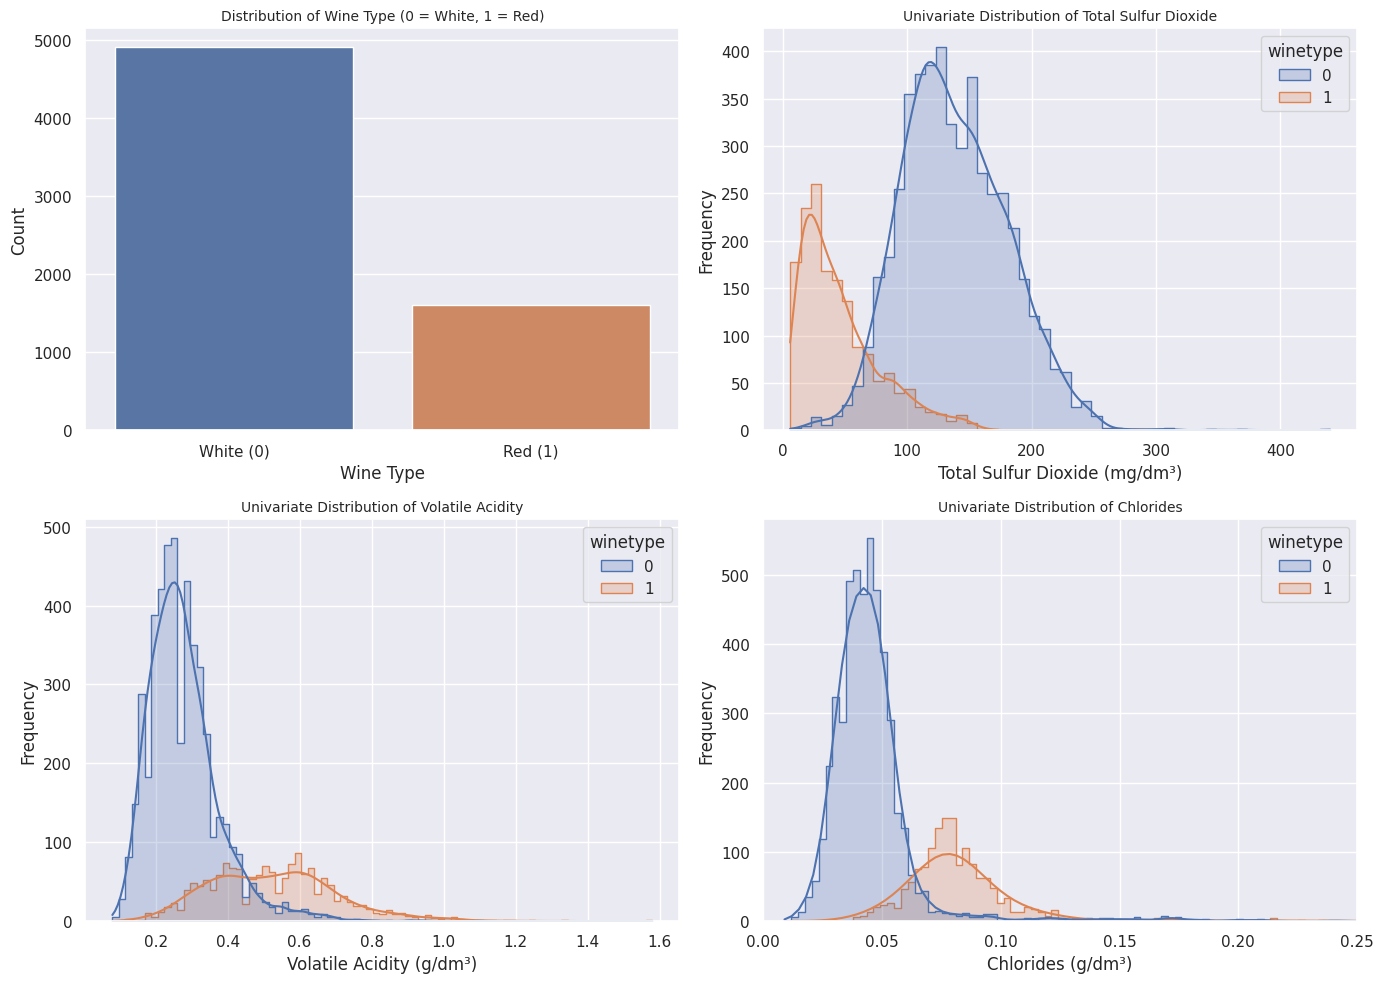

In [26]:
wine_features = ['total sulfur dioxide', 'volatile acidity', 'chlorides']
target = 'winetype'

sns.set_theme()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=wine_df, x=target, ax=axes[0, 0], hue=target, legend=False)
axes[0, 0].set_title('Distribution of Wine Type (0 = White, 1 = Red)', fontsize=10)
axes[0, 0].set_xlabel('Wine Type')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_xticklabels(['White (0)', 'Red (1)'])

sns.histplot(data=wine_df, x='total sulfur dioxide', hue=target, kde=True, ax=axes[0, 1], element='step')
axes[0, 1].set_title('Univariate Distribution of Total Sulfur Dioxide', fontsize=10)
axes[0, 1].set_xlabel('Total Sulfur Dioxide (mg/dm³)')
axes[0, 1].set_ylabel('Frequency')

sns.histplot(data=wine_df, x='volatile acidity', hue=target, kde=True, ax=axes[1, 0], element='step')
axes[1, 0].set_title('Univariate Distribution of Volatile Acidity', fontsize=10)
axes[1, 0].set_xlabel('Volatile Acidity (g/dm³)')
axes[1, 0].set_ylabel('Frequency')

sns.histplot(data=wine_df, x='chlorides', hue=target, kde=True, ax=axes[1, 1], element='step')
axes[1, 1].set_title('Univariate Distribution of Chlorides', fontsize=10)
axes[1, 1].set_xlabel('Chlorides (g/dm³)')
axes[1, 1].set_ylabel('Frequency')

axes[1, 1].set_xlim(0, 0.25)

plt.tight_layout()
plt.show()

### 4. Build a KNN Classification model that evaluates the relationship between the target variable and the 3 features you selected in Question 3. Make sure that you first split the data into training and test sets and tune the hyperparameters where possible using GridSearchCV. Run one version with StandardScaler and one version without it.

In [27]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

X_wine = wine_df[wine_features]
y_wine = wine_df[target]

# 80/20 split
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=42, stratify=y_wine
)

# hyperparameter
param_grid = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance']
}

# w/o standardscaler
knn_unscaled = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
knn_unscaled.fit(X_train_w, y_train_w)

print(f"Best parameters: {knn_unscaled.best_params_}")
print(f"Best cross-validation score: {knn_unscaled.best_score_:.4f}")

unscaled_test_score = knn_unscaled.score(X_test_w, y_test_w)
print(f"Test Set Accuracy: {unscaled_test_score:.4f}")
print("\nTest Set Classification Report:")
print(classification_report(y_test_w, knn_unscaled.predict(X_test_w)))

# standardscaler
scaler_w = StandardScaler()
X_train_w_scaled = scaler_w.fit_transform(X_train_w)
X_test_w_scaled = scaler_w.transform(X_test_w)

knn_scaled = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
knn_scaled.fit(X_train_w_scaled, y_train_w)

print(f"Best parameters: {knn_scaled.best_params_}")
print(f"Best cross-validation score: {knn_scaled.best_score_:.4f}")

scaled_test_score = knn_scaled.score(X_test_w_scaled, y_test_w)
print(f"Test Set Accuracy: {scaled_test_score:.4f}")
print("\nTest Set Classification Report:")
print(classification_report(y_test_w, knn_scaled.predict(X_test_w_scaled)))

Best parameters: {'n_neighbors': 5, 'weights': 'distance'}
Best cross-validation score: 0.9548
Test Set Accuracy: 0.9715

Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      0.92      0.94       320

    accuracy                           0.97      1300
   macro avg       0.97      0.95      0.96      1300
weighted avg       0.97      0.97      0.97      1300

Best parameters: {'n_neighbors': 11, 'weights': 'distance'}
Best cross-validation score: 0.9840
Test Set Accuracy: 0.9885

Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      0.98      0.98       320

    accuracy                           0.99      1300
   macro avg       0.98      0.98      0.98      1300
weighted avg       0.99      0.99      0.99      1300



### 5. Repeat Question 4 two more times, each time using a different linear model that we have learned for classification: Logistic Regression with no regularization, and Logistic Regression with L2 regularization.

In [28]:
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# no regularization
# unscaled
log_reg_none_unscaled = LogisticRegression(penalty=None, random_state=42, max_iter=1000)
log_reg_none_unscaled.fit(X_train_w, y_train_w)

print(f"Test Set Accuracy (Unscaled): {log_reg_none_unscaled.score(X_test_w, y_test_w):.4f}")
print("\nClassification Report (Unscaled):")
print(classification_report(y_test_w, log_reg_none_unscaled.predict(X_test_w)))

# scaled
log_reg_none_scaled = LogisticRegression(penalty=None, random_state=42, max_iter=1000)
log_reg_none_scaled.fit(X_train_w_scaled, y_train_w)

print(f"Test Set Accuracy (Scaled): {log_reg_none_scaled.score(X_test_w_scaled, y_test_w):.4f}")
print("\nClassification Report (Scaled):")
print(classification_report(y_test_w, log_reg_none_scaled.predict(X_test_w_scaled)))


param_grid_l2 = {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

#unscaled
l2_unscaled_grid = GridSearchCV(LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=42), param_grid_l2, cv=5)
l2_unscaled_grid.fit(X_train_w, y_train_w)

print(f"Best parameters: {l2_unscaled_grid.best_params_}")
print(f"Best cross-validation score: {l2_unscaled_grid.best_score_:.4f}")
print(f"Test Set Accuracy: {l2_unscaled_grid.score(X_test_w, y_test_w):.4f}")
print("\nClassification Report (Unscaled with L2):")
print(classification_report(y_test_w, l2_unscaled_grid.predict(X_test_w)))

# scaled
l2_scaled_grid = GridSearchCV(LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=42), param_grid_l2, cv=5)
l2_scaled_grid.fit(X_train_w_scaled, y_train_w)

print(f"Best parameters: {l2_scaled_grid.best_params_}")
print(f"Best cross-validation score: {l2_scaled_grid.best_score_:.4f}")
print(f"Test Set Accuracy: {l2_scaled_grid.score(X_test_w_scaled, y_test_w):.4f}")
print("\nClassification Report (Scaled with L2):")
print(classification_report(y_test_w, l2_scaled_grid.predict(X_test_w_scaled)))

Test Set Accuracy (Unscaled): 0.9685

Classification Report (Unscaled):
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       980
           1       0.92      0.95      0.94       320

    accuracy                           0.97      1300
   macro avg       0.95      0.96      0.96      1300
weighted avg       0.97      0.97      0.97      1300

Test Set Accuracy (Scaled): 0.9685

Classification Report (Scaled):
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       980
           1       0.92      0.95      0.94       320

    accuracy                           0.97      1300
   macro avg       0.95      0.96      0.96      1300
weighted avg       0.97      0.97      0.97      1300

Best parameters: {'C': 1000}
Best cross-validation score: 0.9663
Test Set Accuracy: 0.9685

Classification Report (Unscaled with L2):
              precision    recall  f1-score   support

           0     

### 6. How different are the results of your 3 models? What impact does StandardScalar make? Discuss which final model you would choose to predict new data & why.

KNN had a 97.15 unsclaed and 98.85 scaled. Logistic Regression (no regularization) had 96.85 scaled and unscaled. Logistic regression (L2) had a test accuracy of 96.85 scaled and unscaled. All 3 models had a high accuracy with KNN being the highest.

Standardscaler increased test accuracy from 97.15% to 98.85% and increased cross-validation performance. For logistic regression, standard scaler had no impact.

I would choose KNN regression for its higher accuracy.

### 7. Compare the coefficients for Logistic Regression with and without regularization. Do they agree on which features are important?

In [29]:
coef_unscaled_df = pd.DataFrame({
    'Feature': wine_features,
    'No Regularization Coef': log_reg_none_unscaled.coef_[0],
    'L2 Regularization Coef (C=1000)': l2_unscaled_grid.best_estimator_.coef_[0]
})

coef_scaled_df = pd.DataFrame({
    'Feature': wine_features,
    'No Regularization Coef (Scaled)': log_reg_none_scaled.coef_[0],
    'L2 Regularization Coef (Scaled, C=10)': l2_scaled_grid.best_estimator_.coef_[0]
})

#unscaled
display(coef_unscaled_df)

# scaled
display(coef_scaled_df)

,Feature,No Regularization Coef,L2 Regularization Coef (C=1000)
0,total sulfur dioxide,-0.064723,-0.064607
1,volatile acidity,11.301692,11.290116
2,chlorides,43.119419,42.841686


,Feature,No Regularization Coef (Scaled),"L2 Regularization Coef (Scaled, C=10)"
0,total sulfur dioxide,-3.640101,-3.629933
1,volatile acidity,1.875796,1.871199
2,chlorides,1.488108,1.485105


Yes. The total sulfur dioxide has a strong negative coefficient (-3.63) and both models aagree that sulfur dioxide levels are the strongest indicators of the wine being white. Chlorides has a positive coefficient (1.48), both agree that higher chloride levels is prevalanet in red wine. Volatile acidity has a positive coefficient (1.87), both agree that there's higher volatile acidity in red wine.